# Ares FTSE ex-dividend strategy — single-event ADL comparison

Run one manually specified FTSE ex-dividend event through the same
`FtseExDivDaxHedged` class used by the full Ares backtest. The notebook derives the
long/short signal from the expected index drop, sizes the lagged-beta DAX hedge in
FDAX/Mini-DAX/Micro-DAX, simulates the four execution legs, and can compare combined
P&L and FTSE position with a Grafana production export.

The main parameter cell is deliberately shaped like an ADL launch panel: expected
drop, long/short cutoff, long-leg enable, maximum FT lots, hold time, beta, EUR/GBP,
per-product child sizes, passive/aggressive choices and execution timings are all
explicit. The notebook imports the maintained production strategy rather than
carrying a second implementation.


In [48]:
from pathlib import Path
import re
import sys

ROOT = next((candidate.resolve() for candidate in (
    Path.cwd(),
    Path.cwd() / 'FTSE',
    Path(r'C:\repo\ex_div_dates_research\FTSE'),
) if (candidate / 'ares_exdiv_strategy.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Could not locate the FTSE research folder containing ares_exdiv_strategy.py')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
for p in [Path(r'C:\repo\ares\src'), Path(r'C:\repo\ares\.venv\Lib\site-packages')]:
    if str(p) not in sys.path:
        sys.path.append(str(p))

from datetime import datetime, timedelta, timezone
from zoneinfo import ZoneInfo

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from ares import Backtest, BacktestConfig, ExchangeConfig, FrontMonths, StaticData
from ares_exdiv_strategy import (
    ASSETS, DAX_ASSETS, FEE_PER_LOT_NATIVE, POINT_VALUE, TICK_SIZE,
    ExDivHedgedParams, FtseExDivDaxHedged,
)

LONDON = ZoneInfo('Europe/London')
plt.rcParams.update({'figure.dpi': 120, 'axes.grid': True, 'grid.alpha': .25,
                     'axes.spines.top': False, 'axes.spines.right': False})


## User-defined event and ADL-style parameters

The four contracts must be exact archive symbols. The three DAX-family contracts
must share one expiry. `BETA_60` is the strictly lagged FTSE-on-DAX slope known
before the event; it is not recalculated intraday. `EURGBP_ENTRY` and
`EURGBP_EXIT` are GBP per EUR, ideally the same-expiry 6E/6B midpoint crosses used
by the research export.

Signal rule:

- `EXPECTED_DROP_BPS <= 0`: no trade;
- `0 < EXPECTED_DROP_BPS < LONG_SHORT_CUTOFF_BPS`: long FTSE when
  `ENABLE_LONG_LEG=True`, otherwise no trade;
- `EXPECTED_DROP_BPS >= LONG_SHORT_CUTOFF_BPS`: short FTSE.

`MAX_FT_LOTS` is the absolute active FTSE target. The current strategy does not
scale lots continuously with the expected drop.


In [49]:
# Event and contracts
EVENT_DATE = '2026-10-08'
FT_CONTRACT = 'FTZ26'
FDAX_CONTRACT = 'DAXZ26'
FDXM_CONTRACT = 'FDXMZ26'
FDXS_CONTRACT = 'FDXSZ26'

# Signal and FTSE size
EXPECTED_DROP_BPS = 1.0
LONG_SHORT_CUTOFF_BPS = 5.0
ENABLE_LONG_LEG = True
MAX_FT_LOTS = 20

# Hedge inputs
ENABLE_DAX_HEDGE = True
BETA_60 = 0.60
EURGBP_ENTRY = 0.85             # GBP per EUR at 08:00 London
EURGBP_EXIT = 0.85              # GBP per EUR at the selected exit
HEDGE_ERROR_LIMIT = 0.05        # Micro-DAX used only above this Mini-only mismatch

# Strategy clock and execution windows
ENTRY_TIME_LONDON = '08:00:00'
HOLD_TIME_MIN = 120             # 08:00 -> 10:00 by default
ENTRY_WINDOW_MIN = 5            # passive entry; cross in final CROSS_LAST_SEC
EXIT_WINDOW_MIN = 5             # begin exit this many minutes before flat-by
CROSS_LAST_SEC = 30
PASSIVE_ENTRY = True
PASSIVE_EXIT = True
RUN_PAD_MIN = 2                 # keep trying after flat-by, matching the full backtest

# Per-product maximum child quantities
FT_MAX_CHILD_ORDER_QTY = 2
FDAX_MAX_CHILD_ORDER_QTY = 1
FDXM_MAX_CHILD_ORDER_QTY = 1
FDXS_MAX_CHILD_ORDER_QTY = 1

# Market-data simulation and costs
TICK_DATA_ROOT = Path(r'D:\tick_data\100_ms')
BACKTEST_OUTPUT_DIR = ROOT / 'ares_runs' / 'single_event_hedged'
WARMUP_MIN = 5
TIMER_INTERVAL_SEC = 1
EQUITY_SAMPLE_SEC = 1
SEND_LATENCY_MS = 1
RECV_LATENCY_US = 150
TOUCH_QUEUE_MULTIPLE = 2.0
INCLUDE_BACKTEST_FEES = True
GBPUSD = 1.32                   # USD per GBP; only for USD comparison/reporting

# Optional Grafana comparison
COMPARE_WITH_PROD = True
PROD_FILE = Path(r"C:\Users\DanielFranklin\Downloads\New panel-data-2026-10-09 12_41_18.csv")
PROD_SHEET = 0
PROD_PNL_METRICS = ['Pnl0', 'PNL_USD']
PROD_POSITION_METRICS = ['current_pos']
PROD_PNL_LABEL_FILTER = {'algo': 'FTSE_EXDIV_TRADE'}
PROD_POSITION_LABEL_FILTER = {'algo': 'FTSE_EXDIV_TRADE', 'products': 'FT'}
PROD_PNL_COLUMN = None
PROD_POSITION_COLUMN = None
PROD_PNL_CCY = 'USD'
PROD_TIME_COLUMN = None
PROD_NAIVE_TIMEZONE = 'Europe/London'
PROD_DAY_FIRST = True
PROD_TIME_SHIFT_SEC = 0
PROD_CADENCE_SEC = 15
RESTORE_HIDDEN_SECONDS = True

# Charts only
COMPARISON_PRE_SEC = 5 * 60
ZERO_BASE_EQUITY = True
SQUARE_PNL_GRAPH = False
PLOT_TIMEZONE = 'Europe/London'
SHOW_SCHEDULE_LINES = True
BACKTEST_EQUITY_MULTIPLIER = 1.0
PROD_EQUITY_MULTIPLIER = 1.0


## Derived signal, timing and hedge configuration

Entry starts at the London clock above. If passive execution is enabled, each leg
joins the touch and crosses only during the final `CROSS_LAST_SEC` of its entry or
exit window. At the selected hold time every target is zero. Ares continues through
the short run pad so an incomplete exit can keep crossing.

Contract sizing and order direction are performed by the maintained
`FtseExDivDaxHedged` strategy. FDAX absorbs the largest possible part of the DAX
exposure; Mini-DAX and then Micro-DAX refine only the residual.


In [50]:
event_date = pd.Timestamp(EVENT_DATE).date()


def positive_finite(name, value):
    if (not isinstance(value, (int, float)) or isinstance(value, bool)
            or not np.isfinite(value) or value <= 0):
        raise ValueError(f'{name} must be a positive finite number')


positive_finite('MAX_FT_LOTS', MAX_FT_LOTS)
positive_finite('GBPUSD', GBPUSD)
if int(MAX_FT_LOTS) != MAX_FT_LOTS:
    raise ValueError('MAX_FT_LOTS must be an integer')
if not np.isfinite(EXPECTED_DROP_BPS):
    raise ValueError('EXPECTED_DROP_BPS must be finite')
if not np.isfinite(LONG_SHORT_CUTOFF_BPS) or LONG_SHORT_CUTOFF_BPS < 0:
    raise ValueError('LONG_SHORT_CUTOFF_BPS must be finite and non-negative')
if not isinstance(ENABLE_LONG_LEG, bool) or not isinstance(ENABLE_DAX_HEDGE, bool):
    raise ValueError('ENABLE_LONG_LEG and ENABLE_DAX_HEDGE must be Boolean')

if EXPECTED_DROP_BPS <= 0:
    DIRECTION = None
    SKIP_REASON = 'expected drop is not positive'
elif EXPECTED_DROP_BPS < LONG_SHORT_CUTOFF_BPS:
    DIRECTION = 'long' if ENABLE_LONG_LEG else None
    SKIP_REASON = None if DIRECTION else 'long signal disabled'
else:
    DIRECTION = 'short'
    SKIP_REASON = None

for name, value in {
    'HOLD_TIME_MIN': HOLD_TIME_MIN, 'ENTRY_WINDOW_MIN': ENTRY_WINDOW_MIN,
    'EXIT_WINDOW_MIN': EXIT_WINDOW_MIN, 'TIMER_INTERVAL_SEC': TIMER_INTERVAL_SEC,
    'EQUITY_SAMPLE_SEC': EQUITY_SAMPLE_SEC,
}.items():
    positive_finite(name, value)
if ENTRY_WINDOW_MIN > HOLD_TIME_MIN or EXIT_WINDOW_MIN > HOLD_TIME_MIN:
    raise ValueError('Entry and exit windows cannot be longer than HOLD_TIME_MIN')
if not isinstance(CROSS_LAST_SEC, int) or isinstance(CROSS_LAST_SEC, bool) or CROSS_LAST_SEC < 0:
    raise ValueError('CROSS_LAST_SEC must be a non-negative integer')
if CROSS_LAST_SEC > min(ENTRY_WINDOW_MIN, EXIT_WINDOW_MIN) * 60:
    raise ValueError('CROSS_LAST_SEC cannot exceed the entry or exit window')
if not isinstance(PASSIVE_ENTRY, bool) or not isinstance(PASSIVE_EXIT, bool):
    raise ValueError('PASSIVE_ENTRY and PASSIVE_EXIT must be Boolean')

SLICE_LOTS = {
    'FT': FT_MAX_CHILD_ORDER_QTY,
    'DAX': FDAX_MAX_CHILD_ORDER_QTY,
    'FDXM': FDXM_MAX_CHILD_ORDER_QTY,
    'FDXS': FDXS_MAX_CHILD_ORDER_QTY,
}
for asset, qty in SLICE_LOTS.items():
    if not isinstance(qty, int) or isinstance(qty, bool) or qty < 1:
        raise ValueError(f'{asset} maximum child quantity must be a positive integer')

if ENABLE_DAX_HEDGE and DIRECTION is not None:
    positive_finite('BETA_60', BETA_60)
    positive_finite('EURGBP_ENTRY', EURGBP_ENTRY)
    positive_finite('EURGBP_EXIT', EURGBP_EXIT)
    if not np.isfinite(HEDGE_ERROR_LIMIT) or not 0 <= HEDGE_ERROR_LIMIT < 1:
        raise ValueError('HEDGE_ERROR_LIMIT must be in [0, 1)')

ENTRY_MIN = int(round(ENTRY_WINDOW_MIN))
FLAT_BY_MIN = int(round(HOLD_TIME_MIN))
EXIT_START_MIN = FLAT_BY_MIN - int(round(EXIT_WINDOW_MIN))
PAD_MIN = int(round(RUN_PAD_MIN))
if min(ENTRY_MIN, EXIT_START_MIN, FLAT_BY_MIN, PAD_MIN) < 0:
    raise ValueError('Derived strategy minutes cannot be negative')


## Validate contracts and display the planned schedule


In [51]:
CONTRACTS = {
    'FT': str(FT_CONTRACT).strip().upper(),
    'DAX': str(FDAX_CONTRACT).strip().upper(),
    'FDXM': str(FDXM_CONTRACT).strip().upper(),
    'FDXS': str(FDXS_CONTRACT).strip().upper(),
}
for asset, contract in CONTRACTS.items():
    if not contract.startswith(asset):
        raise ValueError(f'{asset} contract {contract!r} must start with {asset!r}')
dax_expiries = {CONTRACTS[a][len(a):] for a in DAX_ASSETS}
if len(dax_expiries) != 1:
    raise ValueError(f'DAX, FDXM and FDXS must share one expiry, got {CONTRACTS}')

active_assets = tuple(ASSETS if ENABLE_DAX_HEDGE else ('FT',))
front_month_map = {(asset, event_date): CONTRACTS[asset] for asset in active_assets}
tick_files = {
    asset: TICK_DATA_ROOT / asset / event_date.strftime('%Y%m%d') / f'FUT_{CONTRACTS[asset]}.csv'
    for asset in active_assets
}
missing_files = [str(path) for path in tick_files.values() if not path.exists()]
if missing_files:
    raise FileNotFoundError('Missing Ares tick file(s):\n' + '\n'.join(missing_files))


def london_to_utc_naive(day, clock_text):
    clock = datetime.strptime(clock_text, '%H:%M:%S').time()
    local = datetime.combine(day, clock, tzinfo=LONDON)
    return local.astimezone(timezone.utc).replace(tzinfo=None)


strategy_event_ts = london_to_utc_naive(event_date, ENTRY_TIME_LONDON)
entry_deadline_ts = strategy_event_ts + timedelta(minutes=ENTRY_MIN)
unwind_ts = strategy_event_ts + timedelta(minutes=EXIT_START_MIN)
flat_by_ts = strategy_event_ts + timedelta(minutes=FLAT_BY_MIN)
engine_end_ts = flat_by_ts + timedelta(minutes=PAD_MIN)
entry_cross_ts = entry_deadline_ts - timedelta(seconds=CROSS_LAST_SEC)
exit_cross_ts = flat_by_ts - timedelta(seconds=CROSS_LAST_SEC)
if len({event_date, (strategy_event_ts - timedelta(minutes=WARMUP_MIN)).date(), engine_end_ts.date()}) != 1:
    raise ValueError('The event window, warmup and run pad must remain inside one UTC date')

window_start_utc = pd.Timestamp(strategy_event_ts - timedelta(seconds=COMPARISON_PRE_SEC), tz='UTC')
window_end_utc = pd.Timestamp(engine_end_ts, tz='UTC')

events = {}
if DIRECTION is not None:
    events[EVENT_DATE] = {
        'drop_bps': float(EXPECTED_DROP_BPS),
        'direction': DIRECTION,
        'ftse_lots': int(MAX_FT_LOTS),
        'beta_60': float(BETA_60),
        'eurgbp_entry': float(EURGBP_ENTRY),
        'eurgbp_exit': float(EURGBP_EXIT),
        'fx_contract': 'user-defined single-event input',
    }

schedule = pd.DataFrame([
    {'stage': 'entry starts', 'utc': strategy_event_ts},
    {'stage': 'entry crosses', 'utc': entry_cross_ts},
    {'stage': 'entry deadline', 'utc': entry_deadline_ts},
    {'stage': 'exit starts / targets zero', 'utc': unwind_ts},
    {'stage': 'exit crosses', 'utc': exit_cross_ts},
    {'stage': 'flat-by target', 'utc': flat_by_ts},
    {'stage': 'simulation cutoff', 'utc': engine_end_ts},
])
schedule['london'] = (pd.to_datetime(schedule['utc']).dt.tz_localize('UTC')
                      .dt.tz_convert(LONDON).dt.tz_localize(None))
display(schedule)

summary = {
    'event_date': EVENT_DATE,
    'expected_drop_bps': EXPECTED_DROP_BPS,
    'cutoff_bps': LONG_SHORT_CUTOFF_BPS,
    'long_enabled': ENABLE_LONG_LEG,
    'direction': DIRECTION or f'NO TRADE ({SKIP_REASON})',
    'ft_lots': int(MAX_FT_LOTS) if DIRECTION else 0,
    'hold_min': HOLD_TIME_MIN,
    'hedge_enabled': ENABLE_DAX_HEDGE,
    'beta_60': BETA_60,
    'eurgbp_entry': EURGBP_ENTRY,
    'eurgbp_exit': EURGBP_EXIT,
    'hedge_error_limit_pct': HEDGE_ERROR_LIMIT * 100,
    **{f'{asset}_child_max': qty for asset, qty in SLICE_LOTS.items()},
}
display(pd.DataFrame([summary]))
display(pd.DataFrame({'asset': list(tick_files),
                      'contract': [CONTRACTS[a] for a in tick_files],
                      'tick_file': [str(tick_files[a]) for a in tick_files]}))


,stage,utc,london
0,entry starts,2026-10-08 07:00:00,2026-10-08 08:00:00
1,entry crosses,2026-10-08 07:04:30,2026-10-08 08:04:30
2,entry deadline,2026-10-08 07:05:00,2026-10-08 08:05:00
3,exit starts / targets zero,2026-10-08 08:55:00,2026-10-08 09:55:00
4,exit crosses,2026-10-08 08:59:30,2026-10-08 09:59:30
5,flat-by target,2026-10-08 09:00:00,2026-10-08 10:00:00
6,simulation cutoff,2026-10-08 09:02:00,2026-10-08 10:02:00


,event_date,expected_drop_bps,cutoff_bps,long_enabled,direction,ft_lots,hold_min,hedge_enabled,beta_60,eurgbp_entry,eurgbp_exit,hedge_error_limit_pct,FT_child_max,DAX_child_max,FDXM_child_max,FDXS_child_max
0,2026-10-08,1.0,5.0,True,long,20,120,True,0.6,0.85,0.85,5.0,2,1,1,1


,asset,contract,tick_file
0,FT,FTZ26,D:\tick_data\100_ms\FT\20261008\FUT_FTZ26.csv
1,DAX,DAXZ26,D:\tick_data\100_ms\DAX\20261008\FUT_DAXZ26.csv
2,FDXM,FDXMZ26,D:\tick_data\100_ms\FDXM\20261008\FUT_FDXMZ26.csv
3,FDXS,FDXSZ26,D:\tick_data\100_ms\FDXS\20261008\FUT_FDXSZ26.csv


## Maintained Ares strategy

The notebook uses `FtseExDivDaxHedged` from `ares_exdiv_strategy.py` directly.
Consequently its lagged-beta notional target, largest-first FDAX/FDXM/FDXS
decomposition, 5% Micro-DAX refinement rule, opposite hedge direction, passive
touch logic, one-second refresh and IOC crossing behaviour are identical to the
full backtest.


In [52]:
def add_position_history(equity, fills, assets):
    """Attach fill-derived position columns to the regular equity marks."""
    out = equity.sort_values('ts').copy()
    if fills.empty:
        for asset in assets:
            out[f'position_{asset}'] = 0.0
        return out
    side_sign = fills['side'].astype(str).str.upper().map({'BUY': 1, 'SELL': -1})
    if side_sign.isna().any():
        bad = sorted(fills.loc[side_sign.isna(), 'side'].astype(str).unique())
        raise ValueError(f'Unrecognised Ares fill side(s): {bad}')
    fills['signed_qty'] = pd.to_numeric(fills['qty'], errors='raise') * side_sign
    for asset in assets:
        changes = (fills.loc[fills['asset'].eq(asset)]
                   .groupby('ts', as_index=False)['signed_qty'].sum().sort_values('ts'))
        if changes.empty:
            out[f'position_{asset}'] = 0.0
            continue
        changes[f'position_{asset}'] = changes['signed_qty'].cumsum()
        out = pd.merge_asof(out.sort_values('ts'),
                            changes[['ts', f'position_{asset}']],
                            on='ts', direction='backward')
        out[f'position_{asset}'] = out[f'position_{asset}'].fillna(0.0)
    return out


def event_pnl_by_asset(fills):
    """Final P&L using event exit FX for DAX gross and mean FX for DAX fees."""
    rows = []
    fee_fx = (EURGBP_ENTRY + EURGBP_EXIT) / 2.0
    for asset in active_assets:
        leg = fills.loc[fills['asset'].eq(asset)]
        buys = leg.loc[leg['side'].str.upper().eq('BUY')]
        sells = leg.loc[leg['side'].str.upper().eq('SELL')]
        gross_native = (sells.eval('qty * price').sum() - buys.eval('qty * price').sum()) * POINT_VALUE[asset]
        fees_native = leg['qty'].sum() * (FEE_PER_LOT_NATIVE[asset] if INCLUDE_BACKTEST_FEES else 0.0)
        if asset == 'FT':
            gross_gbp, fees_gbp = gross_native, fees_native
        else:
            gross_gbp, fees_gbp = gross_native * EURGBP_EXIT, fees_native * fee_fx
        rows.append({
            'asset': asset, 'buy_qty': buys['qty'].sum(), 'sell_qty': sells['qty'].sum(),
            'gross_native': gross_native, 'fees_native': fees_native,
            'gross_gbp': gross_gbp, 'fees_gbp': fees_gbp,
            'net_gbp': gross_gbp - fees_gbp,
            'net_usd': (gross_gbp - fees_gbp) * GBPUSD,
        })
    return pd.DataFrame(rows).set_index('asset')


## Run the single-event hedged backtest

The engine equity series is expressed in USD for Grafana comparison. For the final
event table, DAX-family gross P&L is converted at `EURGBP_EXIT` and DAX fees at the
mean of entry and exit EUR/GBP, matching the consolidated full-backtest report.


In [53]:
# StaticData converts the single event directly to USD. Native point values remain
# GBP for FT and EUR for the DAX family.
gross_fx_usd = {'FT': float(GBPUSD)}
fee_usd = {'FT': FEE_PER_LOT_NATIVE['FT'] * float(GBPUSD) if INCLUDE_BACKTEST_FEES else 0.0}
for asset in DAX_ASSETS:
    gross_fx_usd[asset] = float(EURGBP_EXIT) * float(GBPUSD)
    fee_usd[asset] = (FEE_PER_LOT_NATIVE[asset] * (EURGBP_ENTRY + EURGBP_EXIT) / 2.0
                      * GBPUSD if INCLUDE_BACKTEST_FEES else 0.0)

static = StaticData(
    point_values={asset: POINT_VALUE[asset] for asset in active_assets},
    tick_sizes={asset: TICK_SIZE[asset] for asset in active_assets},
    fx_rates={asset: gross_fx_usd[asset] for asset in active_assets},
    all_in_fees={asset: fee_usd[asset] for asset in active_assets},
)
strategy = FtseExDivDaxHedged(static, ExDivHedgedParams(
    assets=active_assets,
    trade_from=strategy_event_ts.time(),
    trade_until=engine_end_ts.time(),
    warmup=timedelta(minutes=WARMUP_MIN),
    events=events,
    use_dax_hedge=ENABLE_DAX_HEDGE,
    hedge_error_limit=HEDGE_ERROR_LIMIT,
    eurgbp=EURGBP_ENTRY,
    entry_min=ENTRY_MIN,
    exit_start_min=EXIT_START_MIN,
    flat_by_min=FLAT_BY_MIN,
    cross_last_sec=CROSS_LAST_SEC,
    passive_entry=PASSIVE_ENTRY,
    passive_exit=PASSIVE_EXIT,
    slice_lots=dict(SLICE_LOTS),
    every=timedelta(seconds=TIMER_INTERVAL_SEC),
))
backtest = Backtest(BacktestConfig(
    exchange_config=ExchangeConfig(
        send_latency=timedelta(milliseconds=SEND_LATENCY_MS),
        recv_latency=timedelta(microseconds=RECV_LATENCY_US),
        touch_queue_multiple=TOUCH_QUEUE_MULTIPLE,
    ),
    strategy=strategy,
    dates=[event_date],
    front_months=FrontMonths(front_month_map),
    data_root=str(TICK_DATA_ROOT),
    mark_freq=timedelta(seconds=EQUITY_SAMPLE_SEC),
    out_dir=str(BACKTEST_OUTPUT_DIR),
))
state = backtest.run(show_progress=False)
run_dir = Path(backtest.writer.run_dir)

ares_fills = pd.read_csv(run_dir / 'fills.csv')
ares_equity = pd.read_csv(run_dir / 'equity.csv')
ares_fills['ts'] = pd.to_datetime(ares_fills['ts'], format='mixed', utc=True)
ares_equity['ts'] = pd.to_datetime(ares_equity['ts'], format='mixed', utc=True)
ares_equity = (ares_equity.sort_values('ts').groupby('ts', as_index=False).last()
               .loc[lambda x: x['ts'].between(window_start_utc, window_end_utc)].copy())
ares_equity = add_position_history(ares_equity, ares_fills, active_assets)
ares_equity['comparison_equity'] = ares_equity['equity'] * BACKTEST_EQUITY_MULTIPLIER

if len(ares_fills):
    ares_fills['phase'] = np.where(ares_fills['ts'] < pd.Timestamp(unwind_ts, tz='UTC'),
                                   'entry', 'exit')

plan = strategy.plans.get(EVENT_DATE)
if plan is not None:
    plan_view = {
        'direction': plan['direction'],
        'FT_target': plan['targets'].get('FT', 0),
        'FDAX_target': plan['targets'].get('DAX', 0),
        'FDXM_target': plan['targets'].get('FDXM', 0),
        'FDXS_target': plan['targets'].get('FDXS', 0),
        'beta_60': plan['beta_60'],
        'eurgbp_entry': plan['eurgbp_entry'],
        'target_hedge_gbp': plan['target_hedge_gbp'],
        'actual_hedge_gbp': plan['actual_hedge_gbp'],
        'hedge_error_pct': plan['hedge_error_pct'],
        'mini_only_error_pct': plan['mini_only_error_pct'],
        'used_micro': plan['used_micro'],
    }
    display(pd.DataFrame([plan_view]))
else:
    print(f'No event plan: {SKIP_REASON}')

final_positions = {asset: state.portfolio.qty(CONTRACTS[asset]) for asset in active_assets}
print(f'output={run_dir}; fills={len(ares_fills):,}; final positions={final_positions}; '
      f'engine equity=${state.portfolio.equity():,.2f}')
if any(final_positions.values()):
    print('WARNING: Ares did not finish flat; inspect the fill blotter and run padding')


2026-10-09 12:57:41.449 | INFO     | ares.results:open:66 - writing results to C:\repo\ex_div_dates_research\FTSE\ares_runs\single_event_hedged\20261009_125741_FtseExDivDaxHedged


  plan 2026-10-08: long FT 20 | DAX -2, FDXM -2 | beta 0.600 | EURGBP 0.8500 (user-defined single-event input) | hedge error 2.05%


2026-10-09 12:57:42.712 | INFO     | ares.results:close:121 - 40 fills, equity 6,946.63 -> C:\repo\ex_div_dates_research\FTSE\ares_runs\single_event_hedged\20261009_125741_FtseExDivDaxHedged


,direction,FT_target,FDAX_target,FDXM_target,FDXS_target,beta_60,eurgbp_entry,target_hedge_gbp,actual_hedge_gbp,hedge_error_pct,mini_only_error_pct,used_micro
0,long,20,-2,-2,0,0.6,0.85,1252320.0,1277932.5,2.045204,2.045204,False


output=C:\repo\ex_div_dates_research\FTSE\ares_runs\single_event_hedged\20261009_125741_FtseExDivDaxHedged; fills=40; final positions={'FT': 0, 'DAX': 0, 'FDXM': 0, 'FDXS': 0}; engine equity=$6,946.63


## Load the optional production export

The loader accepts Grafana CSV or Excel exports and can restore repeated
minute-only timestamps to the configured cadence. Combined P&L is comparable only
when the production metric includes the same DAX hedge. The optional production
position series is treated as FTSE position; Ares displays every leg separately.


In [54]:
GRAFANA_LABEL_RE = re.compile(r'(?P<label>[A-Za-z_][A-Za-z0-9_]*)\s*=\s*"(?P<value>[^"]*)"')


def grafana_labels(column):
    text = str(column).strip()
    if not (text.startswith('{') and text.endswith('}')):
        return {}
    labels = {}
    for match in GRAFANA_LABEL_RE.finditer(text):
        key, value = match.group('label'), match.group('value')
        if key in labels:
            raise ValueError(f'Duplicate Grafana label {key!r} in column {column!r}')
        labels[key] = value
    return labels


def choose_time_column(frame, explicit=None):
    if explicit is not None:
        if explicit not in frame.columns:
            raise ValueError(f'Time column {explicit!r} not found; columns={list(frame.columns)}')
        return explicit
    lowered = {str(c).strip().lower(): c for c in frame.columns}
    for candidate in ['time', 'timestamp', 'ts', 'datetime', 'date']:
        if candidate in lowered:
            return lowered[candidate]
    matches = [c for c in frame.columns if not str(c).strip().startswith('{')
               and any(token in str(c).strip().lower() for token in ['time', 'date'])]
    if len(matches) == 1:
        return matches[0]
    raise ValueError(f'Could not uniquely detect the time column; columns={list(frame.columns)}')


def prod_metric_column(frame, what, metrics, label_filter, explicit=None, required=True):
    if explicit is not None:
        matches = [c for c in frame.columns if str(c).strip() == str(explicit).strip()]
        if not matches:
            raise ValueError(f'{what}: column {explicit!r} not found; columns={list(frame.columns)}')
        return matches[0]
    wanted = {str(k): str(v).strip().upper() for k, v in (label_filter or {}).items()}
    for metric in metrics:
        candidates = []
        for column in frame.columns:
            labels = grafana_labels(column)
            name = labels.get('__name__') if labels else str(column).strip()
            if name != metric or (wanted and not labels):
                continue
            if all(labels.get(k, '').strip().upper() == v for k, v in wanted.items()):
                candidates.append(column)
        if len(candidates) == 1:
            return candidates[0]
        if len(candidates) > 1:
            raise ValueError(f'{what}: {len(candidates)} {metric!r} columns match {label_filter}; '
                             f'narrow the label filter or set the exact column. Candidates={candidates}')
    if required:
        raise ValueError(f'{what}: no column with metric in {metrics} matching {label_filter}; '
                         f'columns={list(frame.columns)}')
    return None


def restore_minute_only_cadence(parsed, cadence_sec):
    if cadence_sec <= 0 or 60 % cadence_sec:
        raise ValueError('PROD_CADENCE_SEC must be a positive divisor of 60')
    occurrence = parsed.groupby(parsed, sort=False).cumcount()
    counts = parsed.groupby(parsed, sort=False).transform('size')
    if counts.max() > 60 // cadence_sec:
        raise ValueError(f'A minute contains {int(counts.max())} rows; cannot restore cadence')
    restored = parsed + pd.to_timedelta(occurrence * cadence_sec, unit='s')
    if not restored.dropna().is_monotonic_increasing or restored.duplicated().any():
        raise ValueError('Minute-only timestamps cannot be safely restored in row order')
    return restored


def localise_naive(parsed):
    if RESTORE_HIDDEN_SECONDS and parsed.duplicated().any():
        if not parsed.dt.second.eq(0).all() or not parsed.dt.microsecond.eq(0).all():
            raise ValueError('Duplicate production timestamps include seconds; refusing to shift them')
        parsed = restore_minute_only_cadence(parsed, PROD_CADENCE_SEC)
        print(f'Restored {PROD_CADENCE_SEC}-second timestamps from minute-only values')
    return parsed.dt.tz_localize(PROD_NAIVE_TIMEZONE, ambiguous='infer',
                                 nonexistent='shift_forward').dt.tz_convert('UTC')


def parse_prod_time(values):
    values = pd.Series(values).reset_index(drop=True)
    if pd.api.types.is_datetime64_any_dtype(values):
        parsed = pd.to_datetime(values)
        return parsed.dt.tz_convert('UTC') if parsed.dt.tz is not None else localise_naive(parsed)
    numeric = pd.to_numeric(values, errors='coerce')
    if numeric.notna().mean() > .95:
        magnitude = numeric.dropna().abs().median()
        if 20_000 <= magnitude <= 80_000:
            return localise_naive(pd.to_datetime(numeric, unit='D', origin='1899-12-30').dt.round('ms'))
        unit = 'ns' if magnitude >= 1e17 else 'us' if magnitude >= 1e14 else 'ms' if magnitude >= 1e11 else 's'
        return pd.to_datetime(numeric, unit=unit, utc=True, errors='coerce')
    parsed = pd.to_datetime(values, format='mixed', dayfirst=PROD_DAY_FIRST, errors='coerce')
    if parsed.isna().any():
        examples = values[parsed.isna()].astype(str).head(5).tolist()
        raise ValueError(f'Could not parse production timestamp(s), examples={examples}')
    return localise_naive(parsed) if parsed.dt.tz is None else parsed.dt.tz_convert('UTC')


def load_prod_comparison():
    if not PROD_FILE.exists() or not PROD_FILE.is_file():
        raise FileNotFoundError(f'Set PROD_FILE to the exported Grafana file: {PROD_FILE}')
    raw = (pd.read_excel(PROD_FILE, sheet_name=PROD_SHEET)
           if PROD_FILE.suffix.lower() in {'.xlsx', '.xlsm', '.xls'} else pd.read_csv(PROD_FILE))
    time_col = choose_time_column(raw, PROD_TIME_COLUMN)
    if PROD_PNL_CCY not in {'USD', 'GBP'}:
        raise ValueError("PROD_PNL_CCY must be 'USD' or 'GBP'")
    pnl_col = prod_metric_column(raw, 'P&L', PROD_PNL_METRICS, PROD_PNL_LABEL_FILTER,
                                 PROD_PNL_COLUMN, required=True)
    pos_col = prod_metric_column(raw, 'position', PROD_POSITION_METRICS,
                                 PROD_POSITION_LABEL_FILTER, PROD_POSITION_COLUMN, required=False)
    prod_ts = parse_prod_time(raw[time_col]) + pd.to_timedelta(PROD_TIME_SHIFT_SEC, unit='s')

    def state_frame(column, value_name):
        frame = pd.DataFrame({'ts': prod_ts.to_numpy(),
                              value_name: pd.to_numeric(raw[column], errors='coerce').to_numpy()})
        frame['ts'] = pd.to_datetime(frame['ts'], utc=True)
        frame = (frame.dropna(subset=['ts', value_name]).sort_values('ts')
                 .groupby('ts', as_index=False).last())
        frame = frame[frame['ts'].between(window_start_utc, window_end_utc)].copy()
        if frame.empty:
            raise ValueError(f'Production file has no {value_name} rows in the comparison window')
        return frame

    equity = state_frame(pnl_col, 'equity')
    equity['comparison_equity'] = (equity['equity']
                                   * (1.0 if PROD_PNL_CCY == 'USD' else GBPUSD)
                                   * PROD_EQUITY_MULTIPLIER)
    position = state_frame(pos_col, 'position') if pos_col is not None else None
    cadence = equity['ts'].diff().dt.total_seconds().median() if len(equity) > 1 else np.nan
    print(f'Prod time={time_col!r}; P&L={pnl_col!r}; rows={len(equity):,}; cadence={cadence:g}s')
    print(f'Prod FT position={pos_col!r}' if pos_col is not None else 'Prod FT position not present')
    return equity, position


prod_equity, prod_position = load_prod_comparison() if COMPARE_WITH_PROD else (None, None)


Restored 15-second timestamps from minute-only values
Prod time='Time'; P&L='{__name__="Pnl0", algo="FTSE_EXDIV_TRADE", algo_name="FTSE_EXDIV_TRADE", instance="localhost:8071", job="risk_monitor"}'; rows=365; cadence=15s
Prod FT position not present


## P&L, positions, hedge plan and execution


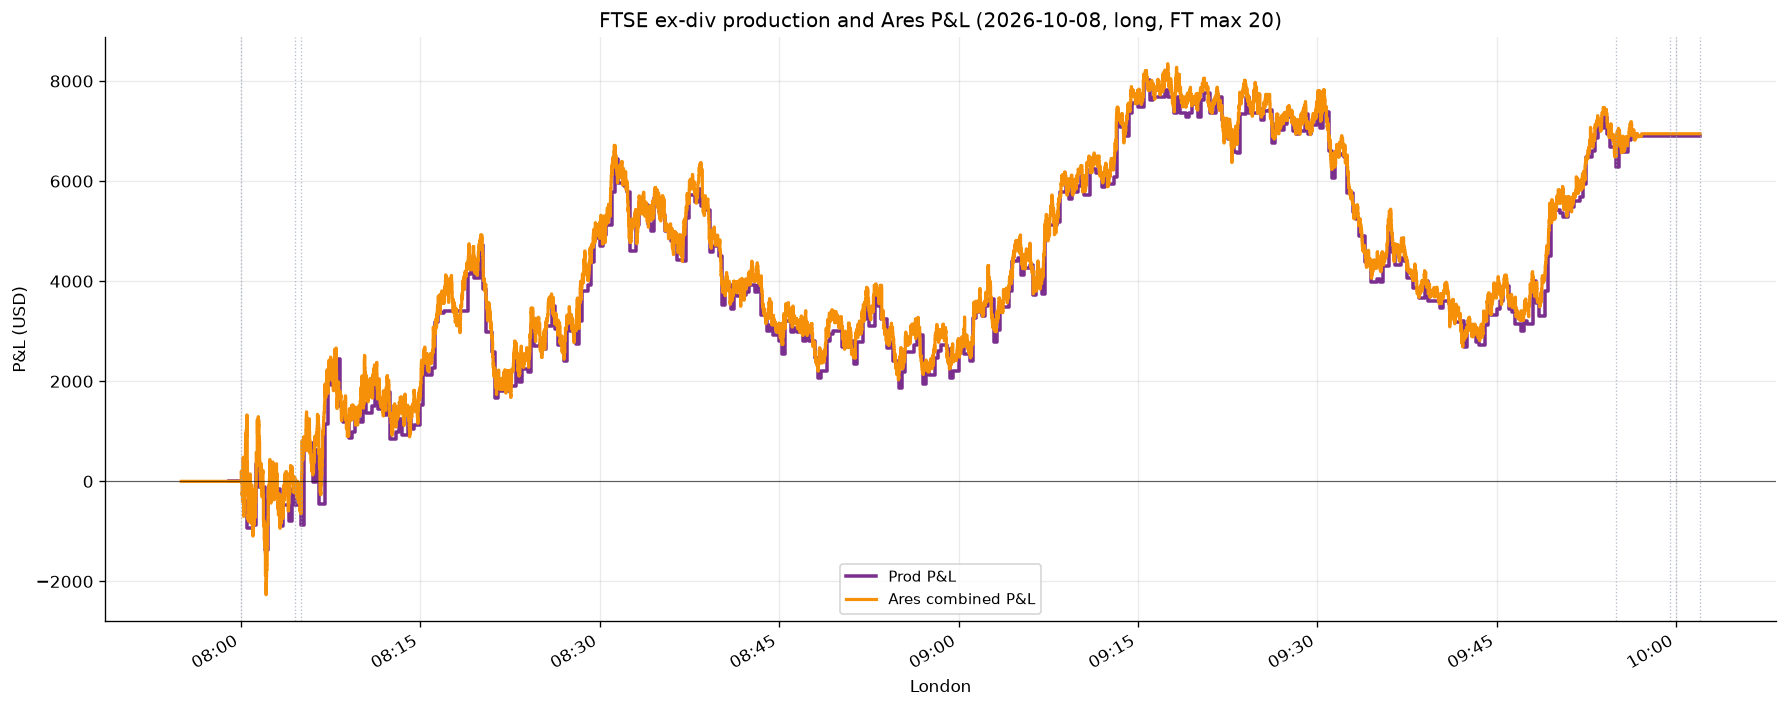

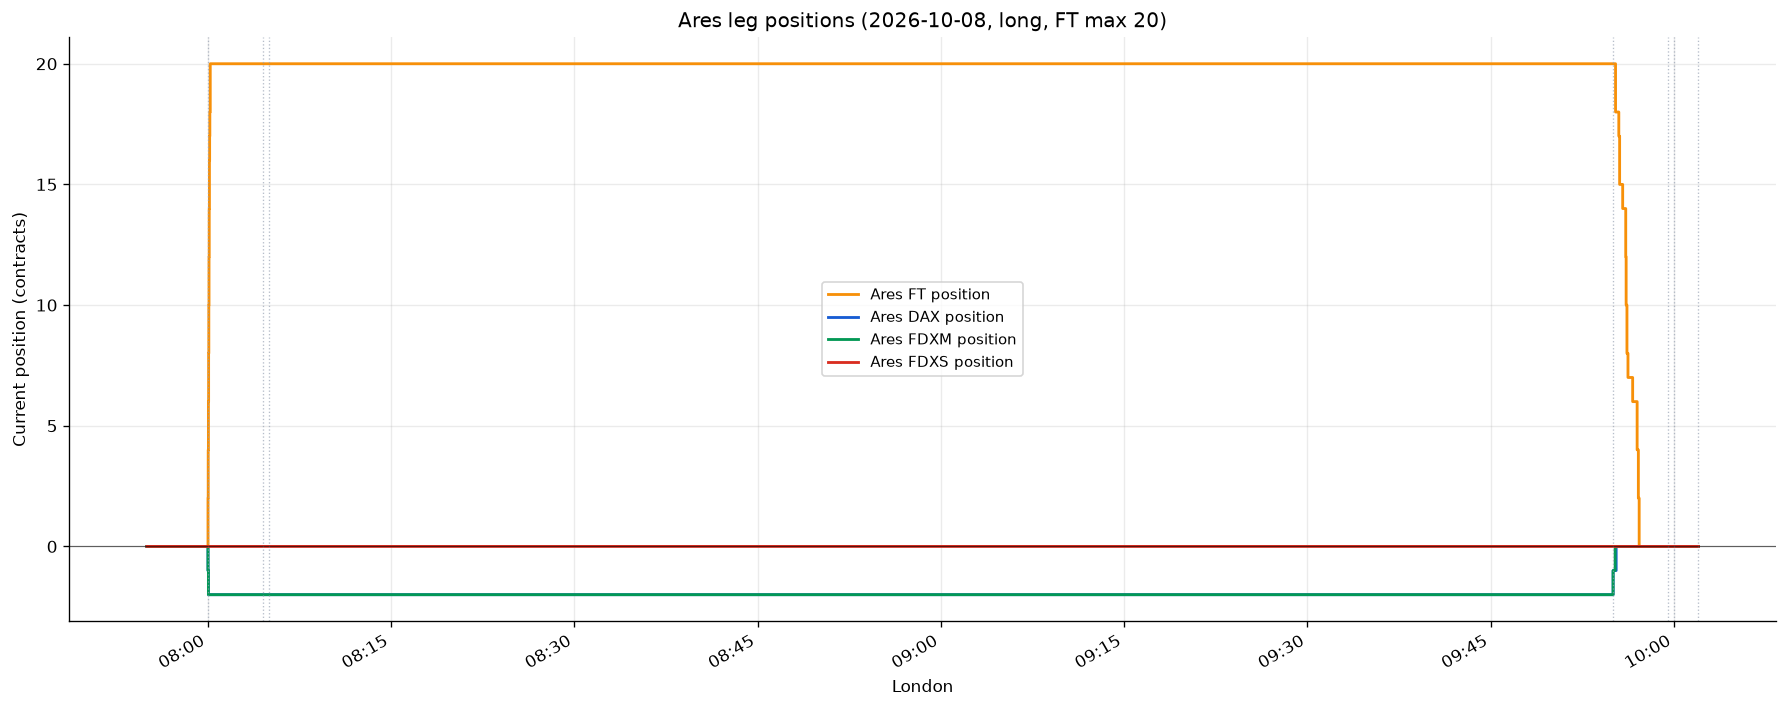

,matched_points,mean_difference_usd,mean_absolute_difference_usd,rmse_usd,maximum_absolute_difference_usd,correlation,final_ares_usd,final_actual_usd
0,365,193.898,229.984,303.881,2260.336,0.9944,6946.632,6909.0


n_fills  qty  maker_pct                 first_fill  \
asset phase side                                                       
FDXM  entry SELL        2    2      100.0 2026-10-08 08:00:00.004903   
FT    entry BUY        18   20       94.4 2026-10-08 08:00:00.324169   
DAX   entry SELL        2    2      100.0 2026-10-08 08:00:00.594163   
      exit  BUY         2    2        0.0 2026-10-08 09:55:00.313566   
FDXM  exit  BUY         2    2      100.0 2026-10-08 09:55:00.550091   
FT    exit  SELL       14   20       50.0 2026-10-08 09:55:12.895092   

                                  last_fill       vwap  
asset phase side                                        
FDXM  entry SELL 2026-10-08 08:00:02.035364  25053.500  
FT    entry BUY  2026-10-08 08:00:11.186027  10430.225  
DAX   entry SELL 2026-10-08 08:00:02.296426  25054.500  
      exit  BUY  2026-10-08 09:55:15.281289  25048.500  
FDXM  exit  BUY  2026-10-08 09:55:10.783313  25047.500  
FT    exit  SELL 2026-10-08 09:57:08.678528  10455.125

,buy_qty,sell_qty,gross_native,fees_native,gross_gbp,fees_gbp,net_gbp,net_usd
asset,,,,,,,,
FT,20,20,4980.0,20.0,4980.0,20.00,4960.00,6547.20
DAX,2,2,300.0,3.2,255.0,2.72,252.28,333.01
FDXM,2,2,60.0,0.8,51.0,0.68,50.32,66.42
FDXS,0,0,0.0,0.0,0.0,0.00,0.00,0.00


Consolidated event net: GBP 5,262.60 / USD 6,946.63


,time_london,asset,contract,phase,side,qty,price,is_maker,order_id
0,2026-10-08 08:00:00.004903,FDXM,FDXMZ26,entry,SELL,1,25058.0,1,3
1,2026-10-08 08:00:00.324169,FT,FTZ26,entry,BUY,2,10435.5,1,1
2,2026-10-08 08:00:00.594163,DAX,DAXZ26,entry,SELL,1,25059.0,1,2
3,2026-10-08 08:00:01.014060,FT,FTZ26,entry,BUY,2,10432.0,1,4
4,2026-10-08 08:00:02.035364,FDXM,FDXMZ26,entry,SELL,1,25049.0,1,9
5,2026-10-08 08:00:02.168178,FT,FTZ26,entry,BUY,1,10430.5,1,7
6,2026-10-08 08:00:02.168178,FT,FTZ26,entry,BUY,1,10430.5,1,7
7,2026-10-08 08:00:02.296426,DAX,DAXZ26,entry,SELL,1,25050.0,1,8
8,2026-10-08 08:00:03.097665,FT,FTZ26,entry,BUY,1,10430.5,1,10
9,2026-10-08 08:00:03.417673,FT,FTZ26,entry,BUY,1,10430.5,1,10


In [55]:
PROD_COLOUR = '#7A2E8E'
ARES_COLOUR = '#F79009'
POSITION_COLOURS = {'FT': '#F79009', 'DAX': '#175CD3', 'FDXM': '#039855', 'FDXS': '#D92D20'}
plot_tz = ZoneInfo(PLOT_TIMEZONE)
plot_tz_label = 'London' if PLOT_TIMEZONE == 'Europe/London' else PLOT_TIMEZONE
direction_label = DIRECTION or 'no trade'
title_suffix = f'{EVENT_DATE}, {direction_label}, FT max {MAX_FT_LOTS}'

if ZERO_BASE_EQUITY:
    ares_equity['comparison_equity'] -= ares_equity['comparison_equity'].iloc[0]
    if prod_equity is not None:
        prod_equity['comparison_equity'] -= prod_equity['comparison_equity'].iloc[0]


def decorate(ax, ylabel, title):
    if SHOW_SCHEDULE_LINES:
        for _, row in schedule.iterrows():
            when = pd.Timestamp(row['utc'], tz='UTC')
            ax.axvline(when, color='#98A2B3', lw=.8, ls=':', alpha=.7)
    ax.axhline(0, color='black', lw=.7, alpha=.6)
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M', tz=plot_tz))
    ax.set(title=title, xlabel=plot_tz_label, ylabel=ylabel)
    ax.legend(fontsize=9)


pnl_figsize = (10, 8) if SQUARE_PNL_GRAPH else (15, 6)
fig, pnl_ax = plt.subplots(figsize=pnl_figsize)
if prod_equity is not None:
    pnl_ax.step(prod_equity['ts'], prod_equity['comparison_equity'], where='post',
                lw=2.1, label='Prod P&L', color=PROD_COLOUR)
pnl_ax.step(ares_equity['ts'], ares_equity['comparison_equity'], where='post',
            lw=1.9, label='Ares combined P&L', color=ARES_COLOUR)
decorate(pnl_ax, 'P&L (USD)', f'FTSE ex-div production and Ares P&L ({title_suffix})')
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

fig, pos_ax = plt.subplots(figsize=(15, 6))
if prod_position is not None:
    pos_ax.step(prod_position['ts'], prod_position['position'], where='post',
                lw=2.2, label='Prod FT position', color=PROD_COLOUR)
for asset in active_assets:
    pos_ax.step(ares_equity['ts'], ares_equity[f'position_{asset}'], where='post',
                lw=1.7, label=f'Ares {asset} position', color=POSITION_COLOURS[asset])
decorate(pos_ax, 'Current position (contracts)', f'Ares leg positions ({title_suffix})')
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

if prod_equity is not None:
    tolerance = pd.Timedelta(seconds=max(EQUITY_SAMPLE_SEC, 1))
    aligned = pd.merge_asof(
        prod_equity[['ts', 'comparison_equity']].sort_values('ts'),
        ares_equity[['ts', 'comparison_equity']].sort_values('ts'),
        on='ts', direction='nearest', tolerance=tolerance,
        suffixes=('_actual', '_ares')).dropna()
    if aligned.empty:
        print('No production/Ares timestamps aligned')
    else:
        aligned['difference'] = aligned['comparison_equity_ares'] - aligned['comparison_equity_actual']
        display(pd.DataFrame([{
            'matched_points': len(aligned),
            'mean_difference_usd': aligned['difference'].mean(),
            'mean_absolute_difference_usd': aligned['difference'].abs().mean(),
            'rmse_usd': np.sqrt(np.mean(aligned['difference'] ** 2)),
            'maximum_absolute_difference_usd': aligned['difference'].abs().max(),
            'correlation': aligned['comparison_equity_ares'].corr(aligned['comparison_equity_actual']),
            'final_ares_usd': aligned['comparison_equity_ares'].iloc[-1],
            'final_actual_usd': aligned['comparison_equity_actual'].iloc[-1],
        }]).round(4))

if len(ares_fills):
    fills_view = ares_fills.assign(
        time_london=ares_fills['ts'].dt.tz_convert(LONDON).dt.tz_localize(None),
        notional=ares_fills['qty'] * ares_fills['price'])
    execution = (fills_view.groupby(['asset', 'phase', 'side'], sort=False)
                 .agg(n_fills=('qty', 'size'), qty=('qty', 'sum'), notional=('notional', 'sum'),
                      maker_pct=('is_maker', 'mean'), first_fill=('time_london', 'min'),
                      last_fill=('time_london', 'max')))
    execution['vwap'] = execution.pop('notional') / execution['qty']
    execution['maker_pct'] *= 100
    display(execution.round({'vwap': 3, 'maker_pct': 1}))
    pnl_by_asset = event_pnl_by_asset(fills_view)
    display(pnl_by_asset.round(2))
    print(f'Consolidated event net: GBP {pnl_by_asset.net_gbp.sum():,.2f} / '
          f'USD {pnl_by_asset.net_usd.sum():,.2f}')
    display(fills_view[['time_london', 'asset', 'contract', 'phase', 'side', 'qty',
                        'price', 'is_maker', 'order_id']].reset_index(drop=True))
else:
    print('Ares produced no fills')
